# 프로모션·업데이트 효과 분석
어뷰저 분석 결과에 따라 **의심 계정 제외** (02_abuser_analysis.ipynb 참고)


### 분석 목표
- **프로모션 효과 분석**
  - 프로모션 기간에 신규, 기존, 복귀 유저의 증감 수 확인
  - 프로모션 기간의 유저 수가 평시 대비 유의하게 증가했는지 검정
- **업데이트 효과 분석**
  - 복귀 지원 프로모션 기간과 종료 후 기존 유저 수 변화를 보고 핫픽스 효과 추정
- **01_EDA.ipynb 파일에서 분석한 내용은 이 파일에서는 제외합니다.**


### 데이터 개요
- **데이터 배경**: 가상 MMORPG **Astrasia Online** 서비스 데이터

- **데이터 기간**: 2026-07-01 ~ 2026-09-28 (90일)

- **분석 대상 테이블**
  - `users.csv`: 유저 정보
  - `daily_activity.csv`: 일별 접속, 플레이타임, 골드, 아이템
  - `funnel_events.csv`: 성장 퍼널 이벤트
  - `payments.csv`: 결제 내역
- **분석 대상 유저 수**: 데이터 기간 중 **1일 이상 접속** 유저 18,401명 중 어뷰저 의심 계정 427명(2.32%)을 제외한 17,974명


### 유저 유형 정의
| 유형 | 정의 |
|---|---|
| 신규 | 가입일(D0)부터 D14까지 해당 유저 |
| 복귀 | 30일 이상 미접속 후 재접속한 날부터 D14까지 |
| 기존 | 신규, 복귀가 아닌 유저 |

- **신규 유저 기준(D14)**: EDA에서 가입 후 리텐션은 D1 38.6% → D14 9.8%로 크게 떨어진 뒤, D30까지는 3.8%p만 감소하며 완만해짐.  
  D14 이후까지 남은 유저는 비교적 꾸준히 재방문한다고 판단해, 그 전까지를 신규 유저로 적용.  
  가입 당일만 신규로 보면 신규 유저층이 너무 작아져, 프로모션 효과 분석에서는 가입 후 방문 기간을 기준으로 신규 유저를 판단.

- **복귀 유저 기준(30일)**: 업계에서 많이 쓰는 기준을 적용.  
  데이터 기간이 90일로 짧아, 기준을 길게 잡으면 복귀 유저로 분류되는 유저가 줄어 복귀 유저 분석이 어려워지기 때문에, 복귀 유저로 판단하기 적절한 기간으로 설정.

- **한계점**: 데이터 시작 일자가 7월 1일부터이기 때문에 복귀 유저는 7월 31일 이후만 구분할 수 있음.  
  이에 따라 여름 축제 1부(7/21~7/27)는 복귀 유저의 판단이 불가해, 신규 vs 기존·복귀 두 그룹으로 비교함.


### 용어 설명
- 유저는 `user_id` 단위이며, 한 사람이 여러 계정을 가지더라도 `user_id`당 한 명의 유저로 간주함.


### 목차
1. 환경설정 및 데이터 확인
2. 프로모션 효과 분석 - 유저 유형 변화
3. 프로모션 효과 분석 - 주요 지표 변화
4. 성장 개편 업데이트 효과 분석
5. 요약

## 1. 환경설정 및 데이터 확인

In [1]:
# 환경 설정
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

# csv 파일 불러오기
users = pd.read_csv("../data/users.csv", parse_dates=["signup_date"])
daily = pd.read_csv("../data/daily_activity.csv", parse_dates=["date"])
events = pd.read_csv("../data/funnel_events.csv", parse_dates=["event_time"])
payments = pd.read_csv("../data/payments.csv", parse_dates=["paid_at"])

# 어뷰저 의심 계정 (02_abuser_analysis 결과)
suspects = pd.read_csv("../output/abuser_analysis/abuser_suspect_list.csv")

In [2]:
# 지수 표시 해제 및 1,000 단위 쉼표 표시
pd.options.display.float_format = '{:,.2f}'.format

In [3]:
# 어뷰저 의심 계정 제외 (이후 모든 분석은 제외한 데이터 기준)
suspect_ids = suspects["user_id"]

# 제외 전 접속 유저 수
n_active_before = daily["user_id"].nunique()

# 4개 테이블에서 의심 계정 제외
users_clean = users[~users["user_id"].isin(suspect_ids)]
daily_clean = daily[~daily["user_id"].isin(suspect_ids)]
events_clean = events[~events["user_id"].isin(suspect_ids)]
payments_clean = payments[~payments["user_id"].isin(suspect_ids)]

# 제외 결과
n_suspects = len(suspect_ids)
n_active_after = daily_clean["user_id"].nunique()
suspect_pct = n_suspects / n_active_before * 100

print(f"기간 중 접속 유저: {n_active_before:,}명")
print(f"제외한 의심 계정: {n_suspects:,}명 ({suspect_pct:.2f}%)")
print(f"분석 대상 유저: {n_active_after:,}명")

기간 중 접속 유저: 18,401명
제외한 의심 계정: 427명 (2.32%)
분석 대상 유저: 17,974명


In [4]:
# 프로모션·업데이트 기간 분류 (EDA와 동일)
periods = {
    "여름 축제 1부": ("2026-07-21", "2026-07-27"),
    "여름 축제 2부": ("2026-08-15", "2026-08-21"),
    "성장 개편 업데이트 이후 핫픽스 전": ("2026-08-30", "2026-09-07"),
    "핫픽스일": ("2026-09-08", "2026-09-08"),
    "복귀 지원 프로모션": ("2026-09-09", "2026-09-15"),
    "복귀 지원 프로모션 종료 후": ("2026-09-16", "2026-09-28"),
}

obs_start = daily_clean["date"].min()     # 데이터 시작일
obs_end = daily_clean["date"].max()       # 데이터 종료일
all_dates = pd.date_range(obs_start, obs_end, freq="D")

# 날짜별 기간 이름 (어느 기간에도 속하지 않으면 "평시")
date_period = pd.Series("평시", index=all_dates)
for name, (start, end) in periods.items():
    in_period = (all_dates >= pd.Timestamp(start)) & (all_dates <= pd.Timestamp(end))
    date_period[in_period] = name

period_order = ["평시"] + list(periods.keys())

# 프로모션별 직전 평시 (비교 기간과 동일 기간·동일 요일, 02_abuser_analysis와 동일)
base_periods = {
    "여름 축제 1부": ("2026-07-14", "2026-07-20"),
    "여름 축제 2부": ("2026-08-08", "2026-08-14"),
    "복귀 지원 프로모션": ("2026-08-22", "2026-08-28"),
}

# 기간별 일수 확인
period_days = date_period.value_counts().reindex(period_order)
display(period_days.to_frame("일수"))

,일수
평시,46
여름 축제 1부,7
여름 축제 2부,7
성장 개편 업데이트 이후 핫픽스 전,9
핫픽스일,1
복귀 지원 프로모션,7
복귀 지원 프로모션 종료 후,13


In [5]:
# 유저 유형 분류

# 유저 유형 기준
NEW_DAYS = 14            # 가입일(D0)부터 D14까지 신규
RETURN_GAP_DAYS = 30     # 30일 이상 미접속 후 재접속하면 복귀
RETURN_DAYS = 14         # 복귀한 날부터 14일까지 복귀 유저 (신규와 같은 길이)

# 복귀 여부를 판단할 수 있는 첫날 (데이터 시작일 + 30일 = 7/31)
type_start = obs_start + pd.Timedelta(days=RETURN_GAP_DAYS)

# 접속 기록에 가입일 붙이기 (유저별 날짜순 정렬)
act = daily_clean.merge(users_clean[["user_id", "signup_date"]], on="user_id")
act = act.sort_values(["user_id", "date"])

# 가입 후 경과일, 직전 접속일과의 간격
act["days_since_signup"] = (act["date"] - act["signup_date"]).dt.days
act["prev_date"] = act.groupby("user_id")["date"].shift()
act["gap_days"] = (act["date"] - act["prev_date"]).dt.days

# 신규: 가입 후 D14까지
is_new = act["days_since_signup"] <= NEW_DAYS

# 복귀한 날: 30일 이상 공백 뒤 접속한 날
# 7/31 이후 로그에 처음 나타난 기존 가입자도 7/1부터 30일 이상 미접속이므로 복귀로 봄
first_seen_late = act["prev_date"].isna() & (act["date"] >= type_start)
is_return_day = ((act["gap_days"] >= RETURN_GAP_DAYS) | first_seen_late) & ~is_new

# 복귀한 날부터 14일까지 복귀 유저
act["return_start"] = act["date"].where(is_return_day)
act["return_start"] = act.groupby("user_id")["return_start"].ffill()
act["days_since_return"] = (act["date"] - act["return_start"]).dt.days
is_return = (act["days_since_return"] <= RETURN_DAYS) & ~is_new

# 유저 유형 (7/31 이전은 복귀를 구분할 수 없어 기존에 복귀가 섞여 있음)
act["user_type"] = np.select([is_new, is_return], ["new", "returning"], "existing")

# 유형별 접속 기록 수 확인 (7/31 이후)
act_typed = act[act["date"] >= type_start]
type_counts = act_typed["user_type"].value_counts()
type_pct = type_counts / type_counts.sum() * 100

print(f"복귀 판단 가능 첫날: {type_start.date()}")
display(pd.DataFrame({"접속 기록 수": type_counts, "비중(%)": type_pct.round(2)}))

복귀 판단 가능 첫날: 2026-07-31


,접속 기록 수,비중(%)
user_type,,
existing,141976,88.78
new,12373,7.74
returning,5573,3.48


## 2. 프로모션 효과 분석 - 유저 유형 변화

**프로모션 내용**

- **여름 축제 1부(7/21 ~ 7/27), 2부(8/15 ~ 8/21)**: 1부와 2부는 같은 내용으로 진행
  - 축제 콘텐츠와 마케팅 광고 진행
  - 한정 코스튬, 프로모션 코인 판매
  - 결제 상품 보너스 지급

- **복귀 지원 프로모션(9/9 ~ 9/15)**: 마케팅 없이 진행
  - 일정 기간 접속하지 않은 유저 대상 **복귀 보상**과 **일반 유저 대상 출석 보상**

### 2-1. 일별 유저 유형별 DAU
- 7/31 이후 일별 DAU를 기존, 신규, 복귀 유저로 나누어 확인함
- 7/31 이전 접속 유저는 기존, 신규 유저로만 확인함

In [6]:
# 일별 유저 유형별 DAU

# 7/31 이후: 신규, 기존, 복귀 세 유형
type_cols = ["new", "existing", "returning"]
dau_type = act_typed.groupby(["date", "user_type"])["user_id"].nunique().unstack(fill_value=0)
dau_type = dau_type[type_cols]

# 전체 기간: 신규 vs 기존·복귀 두 그룹 (여름 축제 1부 비교용)
act["user_group"] = np.where(act["user_type"] == "new", "new", "existing+returning")
group_cols = ["new", "existing+returning"]
dau_group = act.groupby(["date", "user_group"])["user_id"].nunique().unstack(fill_value=0)
dau_group = dau_group[group_cols]

dau_type.head()

user_type,new,existing,returning
date,,,
2026-07-31,289,2220,49
2026-08-01,319,2435,46
2026-08-02,294,2428,45
2026-08-03,267,2254,34
2026-08-04,263,2200,61


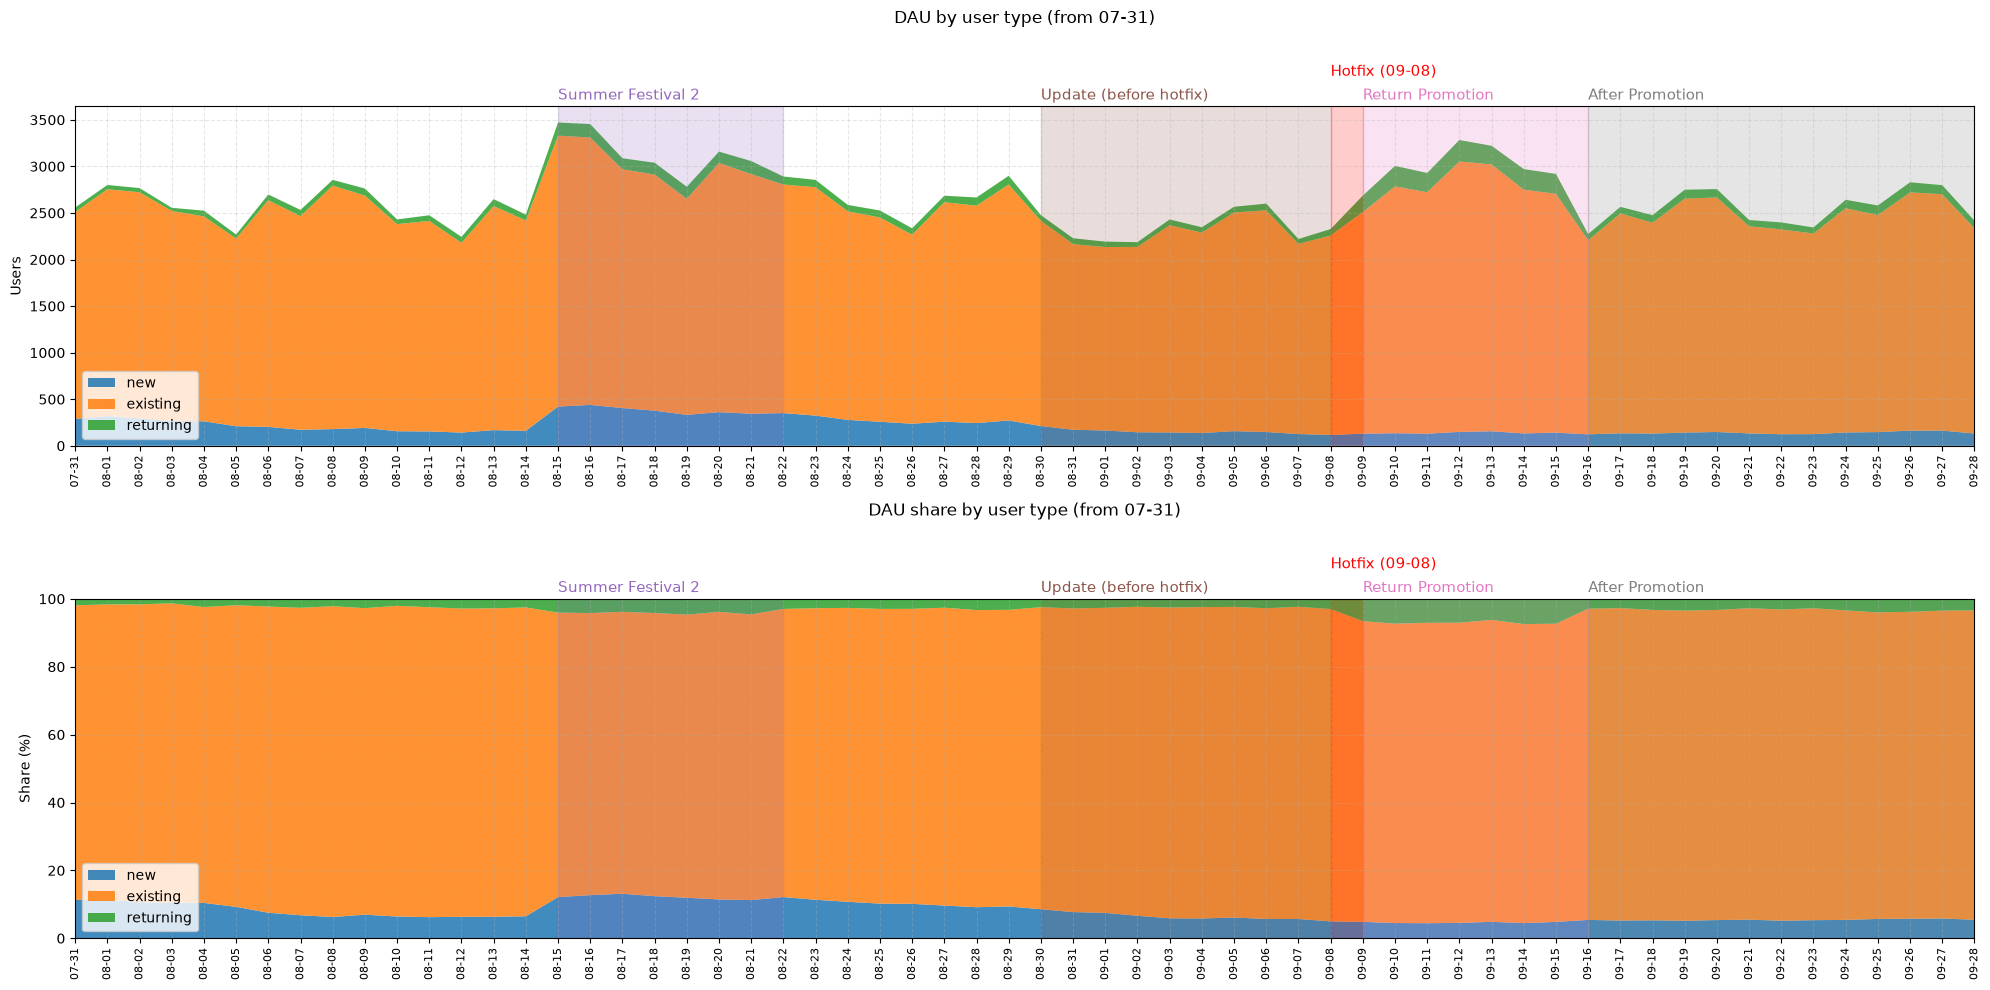

In [7]:
# 시각화: 유형별 DAU 누적 그래프 (위: 실제 유저 수, 아래: 비중 100%)

# 날짜별 유형 비중(%)
dau_type_total = dau_type.sum(axis=1)
dau_type_share = dau_type.div(dau_type_total, axis=0) * 100

# (데이터, 그래프 제목, y축 이름)
charts = [
    (dau_type, "DAU by user type (from 07-31)", "Users"),
    (dau_type_share, "DAU share by user type (from 07-31)", "Share (%)"),
]

# 프로모션·업데이트 기간: (기간 이름, 그래프 표시 이름, 음영 색, 글자 높이)
# 음영 색은 누적 그래프 색(파랑, 주황, 초록)과 겹치지 않게 고름
# 붙어 있는 기간은 글자 높이를 다르게 해서 이름이 겹치지 않게 함
period_styles = [
    ("여름 축제 2부", "Summer Festival 2", "tab:purple", 1.02),
    ("성장 개편 업데이트 이후 핫픽스 전", "Update (before hotfix)", "tab:brown", 1.02),
    ("핫픽스일", "Hotfix (09-08)", "red", 1.09),
    ("복귀 지원 프로모션", "Return Promotion", "tab:pink", 1.02),
    ("복귀 지원 프로모션 종료 후", "After Promotion", "tab:gray", 1.02),
]

fig, axes = plt.subplots(2, 1, figsize=(20, 10))

for ax, (data, title, ylabel) in zip(axes, charts):
    ax.stackplot(data.index, data["new"], data["existing"], data["returning"], labels=type_cols, alpha=0.85)
    ax.set_title(title, pad=60)      # 그래프 위쪽 기간 이름과 겹치지 않게 간격을 둠
    ax.set_ylabel(ylabel)
    ax.set_xlim(data.index.min(), data.index.max())
    ax.legend(loc="lower left")
    ax.grid(alpha=0.3, linestyle="--")

    # 기간 음영과 그래프 위쪽 이름
    for name, label, color, y_text in period_styles:
        start, end = periods[name]
        start_date = pd.Timestamp(start)
        end_date = pd.Timestamp(end) + pd.Timedelta(days=1)
        ax.axvspan(start_date, end_date, color=color, alpha=0.2)
        ax.text(start_date, y_text, label, transform=ax.get_xaxis_transform(), fontsize=11, color=color)

    # x축: 일자별 눈금, 90도 회전
    ax.set_xticks(data.index)
    ax.set_xticklabels(data.index.strftime("%m-%d"), rotation=90, fontsize=8)

axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

### 2-2. 프로모션별 유저 유형 변화 (평시 대비)
- 프로모션 기간의 유저 유형별 일평균 DAU와 평시 대비 증감률을 확인함

    - ① 신규 vs 기존·복귀: 세 프로모션 비교 (평시 기준: 프로모션별 직전 평시)
    - ② 신규, 기존, 복귀: 여름 축제 2부, 복귀 지원 프로모션 비교 (평시 기준: 프로모션별 직전 평시)
    
- 여름 축제 1부는 복귀 유저를 구분할 수 없어 ①로만 확인함

- **평시 기준**: 프로모션 직전의 평시(프로모션·업데이트가 없는 날) 중 비교 기간과 동일 기간·동일 요일로 정함

| 프로모션 | 비교 기간 | 평시 |
|---|---|---|
| 여름 축제 1부 | 7/21 ~ 7/27 | **7/14 ~ 7/20** |
| 여름 축제 2부 | 8/15 ~ 8/21 | **8/8 ~ 8/14** |
| 복귀 지원 프로모션 | 9/9 ~ 9/15 | **8/22 ~ 8/28** |

- 복귀 지원 프로모션의 평시는 여름 축제 2부 직후라 잔여 효과가 포함되었을 가능성이 있음

In [8]:
# 프로모션별 유저 유형 일평균 DAU와 직전 평시 대비 증감률

# 프로모션별 직전 평시 일평균, 프로모션 일평균, 평시 대비 증감률(%)을 만드는 함수
# 평시는 프로모션별 직전 평시 (base_periods)
def summarize_vs_base(df_by_date, target_periods):
    labels = date_period.reindex(df_by_date.index)

    rows = []
    for col in df_by_date.columns:
        for name in target_periods:
            base_start, base_end = base_periods[name]
            base_label = base_start + "~" + base_end
            base_mean = df_by_date.loc[base_start:base_end, col].mean()
            promo_mean = df_by_date.loc[labels == name, col].mean()
            change = (promo_mean / base_mean - 1) * 100

            rows.append({"지표": col, "프로모션": name, "평시 기간": base_label,
                         "평시 일평균": base_mean, "프로모션 일평균": promo_mean, "평시 대비(%)": change})

    result = pd.DataFrame(rows).set_index(["지표", "프로모션"])
    return result


# 표시 형식
vs_base_fmt = {"평시 일평균": "{:,.0f}", "프로모션 일평균": "{:,.0f}", "평시 대비(%)": "{:+.1f}%"}


# ① 신규 vs 기존·복귀: 세 프로모션 (직전 평시 기준)
group_periods = ["여름 축제 1부", "여름 축제 2부", "복귀 지원 프로모션"]
group_table = summarize_vs_base(dau_group, group_periods)
print("\n[① 신규 vs 기존·복귀]")
display(group_table.style.format(vs_base_fmt))

# ② 신규, 기존, 복귀: 여름 축제 2부, 복귀 지원 프로모션 (직전 평시 기준, 유형 구분은 7/31 이후만 가능)
type_periods = ["여름 축제 2부", "복귀 지원 프로모션"]
type_table = summarize_vs_base(dau_type, type_periods)
print("\n[② 신규, 기존, 복귀]")
display(type_table.style.format(vs_base_fmt))



[① 신규 vs 기존·복귀]



[② 신규, 기존, 복귀]


### 2-3. 통계적 가설 검정 1: 직전 기간 평시 vs 프로모션 차이 유의성 검증
- **목적**: 각 프로모션 기간의 유저 유형별 DAU가 직전 기간 평시와 차이가 있는지 확인하고자 함

| 검정 | 비교 | 평시 기준 |
|---|---|---|
| ① 신규, 기존·복귀 | 평시 vs 세 프로모션 각각 (여름 축제 1부, 2부, 복귀 지원 프로모션) | 1부 **7/14~7/20**, 2부 **8/8~8/14**, 복귀 지원 **8/22~8/28** |
| ② 기존, 복귀 | 평시 vs 여름 축제 2부, 복귀 지원 프로모션 각각 | 2부 **8/8~8/14**, 복귀 지원 **8/22~8/28** |

- **방법**
    - 평시 일별 DAU와 프로모션 기간 일별 DAU를 Mann-Whitney U 검정(양측)으로 비교함
    - 각 프로모션을 개별 이벤트로 평가하므로, 프로모션·유형별로 직전 평시와 각각 비교함
    - 증가인지 감소인지는 평시 대비(%) 부호로 판단함

- **유의수준**: α = 0.05

- **가설**
    - H0(귀무가설): 프로모션 기간의 일별 DAU는 평시와 **차이가 없다**
    - H1(대립가설): 프로모션 기간의 일별 DAU는 평시와 **차이가 있다**

In [9]:
# 평시 대비 검정에 쓸 함수
promo_periods = ["여름 축제 1부", "여름 축제 2부", "복귀 지원 프로모션"]


# 평시 vs 각 프로모션: Mann-Whitney U 검정 (프로모션별 개별 비교, 다중 비교 보정 없음)
# 평시는 프로모션별 직전 평시 (base_periods)
def compare_to_base(df_by_date, target_periods):
    labels = date_period.reindex(df_by_date.index)
    rows = []
    for col in df_by_date.columns:
        for name in target_periods:
            base_start, base_end = base_periods[name]
            base_label = base_start + "~" + base_end
            base_values = df_by_date.loc[base_start:base_end, col]
            base_mean = base_values.mean()

            promo_values = df_by_date.loc[labels == name, col]
            promo_mean = promo_values.mean()
            change = (promo_mean / base_mean - 1) * 100
            p_value = mannwhitneyu(promo_values, base_values, alternative="two-sided").pvalue

            rows.append({"지표": col, "프로모션": name, "평시 기간": base_label,
                         "평시 일평균": base_mean, "프로모션 일평균": promo_mean, "평시 대비(%)": change,
                         "p-value": p_value, "유의(p<0.05)": p_value < 0.05})

    result = pd.DataFrame(rows).set_index(["지표", "프로모션"])
    return result


# 표시 형식
base_fmt = {"평시 일평균": "{:,.0f}", "프로모션 일평균": "{:,.0f}", "평시 대비(%)": "{:+.1f}%", "p-value": "{:.4f}"}


# ① 신규, 기존·복귀: 직전 평시 vs 세 프로모션
group_base_test = compare_to_base(dau_group, promo_periods)
print("\n[① 신규, 기존·복귀]")
display(group_base_test.style.format(base_fmt))


[① 신규, 기존·복귀]


In [10]:
# ② 기존, 복귀: 직전 평시 vs 여름 축제 2부, 복귀 지원 프로모션
type_base_test = compare_to_base(dau_type[["existing", "returning"]], ["여름 축제 2부", "복귀 지원 프로모션"])
print("\n[② 기존, 복귀]")
display(type_base_test.style.format(base_fmt))


[② 기존, 복귀]


**결과 해석**
- True는 p-value < 0.05로 평시와의 차이가 유의함, False는 유의하지 않음을 뜻함

**요약**
- 기존·복귀 유저(①)와 기존 유저, 복귀 유저(②): 모든 프로모션에서 p-value 0.05 미만으로, 평시와 비교하여 차이가 유의함
- 신규 유저는 복귀 지원 프로모션에서 감소(직전 평시 대비 -50.1%)했고, 여름 축제 1부·2부에서는 유의하게 증가함

### **요점**
- 마케팅 광고가 포함된 프로모션에서 신규 유저 유입이 많아, **신규 유저는 마케팅에 크게 반응하는 것으로 보임**  
  (직전 평시 대비 여름 축제 1부 +146.8%, 2부 +132.6%)
- 복귀 지원 프로모션은 마케팅을 하지 않았음에도 여름 축제 2부보다 복귀 유저가 더 많이 증가함 (직전 평시 대비 +174.3% vs +104.7%).  
  **복귀 지원 프로모션에서 사용한 방법(복귀 보상 등)이 복귀 유저를 끌어오는 데 효과적**이었던 것으로 보임

## 3. 프로모션 효과 분석 - 주요 지표 변화

### 3-1. 프로모션별 주요 지표 변화 (평시 대비)
- 프로모션 기간의 DAU, 매출, 결제 전환율, ARPU, ARPPU 일평균과 평시 대비 증감률을 확인함  
  (평시: 1부 **7/14~7/20**, 2부 **8/8~8/14**, 복귀 지원 **8/22~8/28**)
- 일별로 결제 전환율 = 결제 유저 수 ÷ DAU, ARPU = 매출 ÷ DAU, ARPPU = 매출 ÷ 결제 유저 수를 계산함

In [11]:
# 프로모션별 주요 지표 일평균과 직전 평시 대비 증감률: DAU, 매출, 결제 전환율, ARPU, ARPPU

# 일별 DAU
dau = daily_clean.groupby("date")["user_id"].nunique()

# 일별 결제 유저 수, 매출 (결제가 없는 날은 0)
pay_date = payments_clean["paid_at"].dt.normalize()
payers = payments_clean.groupby(pay_date)["user_id"].nunique().reindex(all_dates, fill_value=0)
revenue = payments_clean.groupby(pay_date)["amount_krw"].sum().reindex(all_dates, fill_value=0)

# 결제 전환율(%), ARPU, ARPPU
pay_conv = payers / dau * 100
arpu = revenue / dau
arppu = revenue / payers

daily_metrics = pd.DataFrame({
    "DAU": dau,
    "revenue": revenue,
    "pay_conv(%)": pay_conv,
    "ARPU": arpu,
    "ARPPU": arppu,
})

# 프로모션별 직전 평시 일평균과 평시 대비 증감률
metric_table = summarize_vs_base(daily_metrics, promo_periods)

# 지표별 출력 (결제 전환율만 소수점 둘째 자리)
for col in daily_metrics.columns:
    value_fmt = "{:.2f}" if col == "pay_conv(%)" else "{:,.0f}"
    fmt = {"평시 일평균": value_fmt, "프로모션 일평균": value_fmt, "평시 대비(%)": "{:+.1f}%"}
    print(f"\n[{col}]")
    display(metric_table.loc[col].style.format(fmt))


[DAU]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%)
프로모션,,,,
여름 축제 1부,2026-07-14~2026-07-20,"2,458","3,308",+34.6%
여름 축제 2부,2026-08-08~2026-08-14,"2,556","3,150",+23.2%
복귀 지원 프로모션,2026-08-22~2026-08-28,"2,649","3,002",+13.3%



[revenue]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%)
프로모션,,,,
여름 축제 1부,2026-07-14~2026-07-20,"991,414","2,195,757",+121.5%
여름 축제 2부,2026-08-08~2026-08-14,"1,091,200","1,912,743",+75.3%
복귀 지원 프로모션,2026-08-22~2026-08-28,"1,114,929","1,394,014",+25.0%



[pay_conv(%)]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%)
프로모션,,,,
여름 축제 1부,2026-07-14~2026-07-20,1.02,1.69,+65.8%
여름 축제 2부,2026-08-08~2026-08-14,1.03,1.48,+44.5%
복귀 지원 프로모션,2026-08-22~2026-08-28,1.05,1.12,+7.1%



[ARPU]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%)
프로모션,,,,
여름 축제 1부,2026-07-14~2026-07-20,402,662,+64.7%
여름 축제 2부,2026-08-08~2026-08-14,423,606,+43.4%
복귀 지원 프로모션,2026-08-22~2026-08-28,419,462,+10.2%



[ARPPU]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%)
프로모션,,,,
여름 축제 1부,2026-07-14~2026-07-20,"39,561","39,257",-0.8%
여름 축제 2부,2026-08-08~2026-08-14,"41,111","41,016",-0.2%
복귀 지원 프로모션,2026-08-22~2026-08-28,"40,117","41,155",+2.6%


### 3-2. 통계적 가설 검정: 평시 vs 프로모션 차이 유의성 검증
- **목적**: 각 프로모션 기간의 DAU, 매출, 결제 전환율, ARPU, ARPPU가 직전 평시와 차이가 있는지 확인하고자 함  
  (평시: 1부 **7/14~7/20**, 2부 **8/8~8/14**, 복귀 지원 **8/22~8/28**)

- **방법**
    - 평시 일별 값과 프로모션 기간 일별 값을 Mann-Whitney U 검정(양측)으로 비교함
    - 각 프로모션을 개별 이벤트로 평가하므로, 프로모션·지표별로 직전 평시와 각각 비교함
    - 증가인지 감소인지는 평시 대비(%) 부호로 판단함
    - 프로모션 기간이 각 7일로 표본이 작아 정규분포 여부를 확인하기 어렵고 튀는 값이 있어, 순위로 비교하는 비모수 검정을 사용함

- **유의수준**: α = 0.05

- **가설**
    - H0(귀무가설): 프로모션 기간의 일별 지표는 평시와 **차이가 없다**
    - H1(대립가설): 프로모션 기간의 일별 지표는 평시와 **차이가 있다**

- **한계점**
    - 표본이 작아 검정력이 낮을 수 있어, '유의하지 않음'은 '차이 없음'을 의미하지 않음
    - 선행 프로모션의 잔여 효과가 평시에 포함될 수 있음

In [12]:
# 주요 지표: 직전 평시 vs 프로모션 검정
metric_base_test = compare_to_base(daily_metrics, promo_periods)

for col in daily_metrics.columns:
    value_fmt = "{:.2f}" if col == "pay_conv(%)" else "{:,.0f}"
    fmt = {**base_fmt, "평시 일평균": value_fmt, "프로모션 일평균": value_fmt}
    print(f"\n[{col}]")
    display(metric_base_test.loc[col].style.format(fmt))


[DAU]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%),p-value,유의(p<0.05)
프로모션,,,,,,
여름 축제 1부,2026-07-14~2026-07-20,"2,458","3,308",+34.6%,0.0006,True
여름 축제 2부,2026-08-08~2026-08-14,"2,556","3,150",+23.2%,0.0012,True
복귀 지원 프로모션,2026-08-22~2026-08-28,"2,649","3,002",+13.3%,0.0023,True



[revenue]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%),p-value,유의(p<0.05)
프로모션,,,,,,
여름 축제 1부,2026-07-14~2026-07-20,"991,414","2,195,757",+121.5%,0.0006,True
여름 축제 2부,2026-08-08~2026-08-14,"1,091,200","1,912,743",+75.3%,0.0006,True
복귀 지원 프로모션,2026-08-22~2026-08-28,"1,114,929","1,394,014",+25.0%,0.0728,False



[pay_conv(%)]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%),p-value,유의(p<0.05)
프로모션,,,,,,
여름 축제 1부,2026-07-14~2026-07-20,1.02,1.69,+65.8%,0.0006,True
여름 축제 2부,2026-08-08~2026-08-14,1.03,1.48,+44.5%,0.0006,True
복귀 지원 프로모션,2026-08-22~2026-08-28,1.05,1.12,+7.1%,0.4557,False



[ARPU]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%),p-value,유의(p<0.05)
프로모션,,,,,,
여름 축제 1부,2026-07-14~2026-07-20,402,662,+64.7%,0.0006,True
여름 축제 2부,2026-08-08~2026-08-14,423,606,+43.4%,0.0006,True
복귀 지원 프로모션,2026-08-22~2026-08-28,419,462,+10.2%,0.4557,False



[ARPPU]


,평시 기간,평시 일평균,프로모션 일평균,평시 대비(%),p-value,유의(p<0.05)
프로모션,,,,,,
여름 축제 1부,2026-07-14~2026-07-20,"39,561","39,257",-0.8%,0.9015,False
여름 축제 2부,2026-08-08~2026-08-14,"41,111","41,016",-0.2%,1.0000,False
복귀 지원 프로모션,2026-08-22~2026-08-28,"40,117","41,155",+2.6%,0.8048,False


### **요점**
- **여름 축제 1부·2부**는 ARPPU를 제외한 모든 지표가 직전 평시 대비 유의하게 증가함  
  - 매출: 1부 +121.5%, 2부 +75.3%  
  - 결제 전환율: 1부 +65.8%, 2부 +44.5%  
  - ARPU: 1부 +64.7%, 2부 +43.4%  
  - DAU: 1부 +34.6%, 2부 +23.2%

- **ARPPU**는 세 프로모션 모두 직전 평시와 차이가 유의하지 않음 (1부 -0.8%, 2부 -0.2%, 복귀 지원 +2.6%).  
  매출은 DAU × 결제 전환율 × ARPPU로 나눌 수 있어, 축제의 매출 증가는 결제 유저의 1인당 결제액보다 **DAU와 결제 전환율 증가**의 영향이 큰 것으로 보임

- **복귀 지원 프로모션**은 DAU만 직전 평시 대비 유의하게 증가(+13.3%)했고, **매출(+25.0%, p-value = 0.2185), 결제 전환율(+7.1%), ARPU(+10.2%)는 차이가 유의하지 않음**.  
  복귀 유저는 늘었지만 결제로 이어지지 않았을 가능성이 있음
  - 복귀 지원 프로모션은 직전 평시(8/22~8/28)에 여름 축제 2부의 잔여 효과가 포함되었을 가능성이 있어 해석에 주의가 필요함

- 매출 및 결제 전환율 상승에 `프로모션 코인과 한정 코스튬 판매, 결제 상품 보너스`가 영향을 주었을 수 있으나,  
  주어진 데이터로는 해당 상품의 판매 내역을 확인할 수 없어 추후 확인이 필요함.

## 4. 성장 개편 업데이트 효과 분석
`01_EDA.ipynb`의 4장(DAU, WAU)에서 남긴 질문을 확인하기 위한 추가 분석

- **성장 개편 업데이트(8/30) 이후**: 핫픽스(9/8)까지 평시보다 낮은 DAU(직전 평시 **8/22~8/29** 대비 -11.9%)가 이어졌음.  
  복귀 지원 프로모션 기간(9/9~9/15)에는 DAU가 직전 평시 **8/22~8/28** 대비 +13.3%로 회복되었고, 프로모션 종료 후(9/20~9/28)에는 직전 평시 **8/22~8/29** 대비 -3.9%였음.

  - 업데이트 이후 떨어졌던 DAU가 핫픽스로 필드 사냥 경험치 하향폭을 완화한 뒤 회복되어, 경험치 하향이 유저 접속 감소에 영향을 줬을 가능성이 있음.  
    다만 핫픽스 다음 날 복귀 지원 프로모션이 시작되어 DAU 회복에 두 요인이 함께 작용했을 수 있으므로, 핫픽스와 프로모션의 영향을 나누어 확인하고자 함.


**업데이트 내용**

- **성장 개편 업데이트 내용(8/30)**
  - ① 필드 사냥 경험치 20% 하향(성장 속도 조정)
  - ② Lv45 이상 신규 지역 추가
  - ③ 장비 강화 패키지 판매 시작
  - ④ 대용량 클라이언트 패치(모바일은 업데이트 완료까지 시간이 걸림)

- **핫픽스 내용(9/8)**
  - 필드 경험치 하향폭을 20% → 10%로 완화 (09-08부터 적용)

- **복귀 지원 프로모션 내용(9/9 ~ 9/15)**
  - 일정 기간 접속하지 않은 유저 대상 **복귀 보상**과 **일반 유저 대상 출석 보상**

### **가설 설정**
DAU 회복의 원인을 나누어 보기 위해, 복귀 지원 프로모션 기간(9/9 ~ 9/15)과 프로모션 종료 후(9/16 ~ 9/28)를 나누어 확인함. 

복귀 지원 프로모션에는 일반 유저 대상 출석 보상도 포함되어 있어, 프로모션 기간에 기존 유저가 늘어난 것도 보상의 영향일 수 있음.  
따라서 프로모션 종료 후에도 기존 유저가 핫픽스 전(8/30~9/7)보다 높게 유지되는지를 함께 확인함.  

핫픽스의 영향 판단을 위해 아래 두 기간의 기존 유저 수를 비교함.
- 성장 개편 업데이트 이후 핫픽스 전(8/30 ~ 9/7)
- 프로모션 종료 후(**9/20 ~ 9/28**)
  - 프로모션 종료 후(9/16 ~ 9/28) 중 핫픽스 전과 동일 기간·동일 요일(일~월요일, 총 9일)로 맞춘 기간임
  - 평시는 두 기간 모두 업데이트 직전 평시 **8/22 ~ 8/29**(8일)와 비교함

**결과 판단**
* 기존 유저 수 증가 → 핫픽스(경험치 하향폭 완화)의 효과로 판단
* 기존 유저 수 유지·감소 → 핫픽스의 효과는 적었고, 프로모션의 영향이 있었을 것으로 판단

### 4-1. 핫픽스 전후 기존 유저 DAU 비교
- 평시: 업데이트 직전 평시 **8/22~8/29**(8일). 업데이트 직전에 프로모션이 아닌 날이 8일뿐이라 8일로 비교함
- 종료 후: 핫픽스 전과 동일 기간·동일 요일(일~월요일, 총 9일)로 맞춘 **9/20~9/28**

In [13]:
# 기간별 기존 유저 일평균 DAU와 평시 대비, 핫픽스 전 대비 증감률
# 평시: 업데이트 직전 평시 8/22~8/29 (8일)
# 종료 후: 핫픽스 전과 동일 기간·동일 요일로 맞춘 9/20~9/28 (일~월요일, 9일)
hotfix_base = ("2026-08-22", "2026-08-29")
hotfix_periods = {
    "성장 개편 업데이트 이후 핫픽스 전": ("2026-08-30", "2026-09-07"),
    "복귀 지원 프로모션 종료 후": ("2026-09-20", "2026-09-28"),
}

existing_daily = dau_type["existing"]

# 평시 일평균
hotfix_base_start, hotfix_base_end = hotfix_base
hotfix_base_label = hotfix_base_start + "~" + hotfix_base_end
existing_base_mean = existing_daily.loc[hotfix_base_start:hotfix_base_end].mean()

# 핫픽스 전 일평균
before_start, before_end = hotfix_periods["성장 개편 업데이트 이후 핫픽스 전"]
before_hotfix_mean = existing_daily.loc[before_start:before_end].mean()

# 기간별 일평균, 평시 대비, 핫픽스 전 대비 증감률(%)
rows = []
for name, (start, end) in hotfix_periods.items():
    period_mean = existing_daily.loc[start:end].mean()
    change_base = (period_mean / existing_base_mean - 1) * 100
    change_before = (period_mean / before_hotfix_mean - 1) * 100
    period_label = start + "~" + end

    rows.append({"기간": name, "비교 기간": period_label, "평시 기간": hotfix_base_label,
                 "평시 일평균": existing_base_mean, "기존 유저 일평균": period_mean,
                 "평시 대비(%)": change_base, "핫픽스 전 대비(%)": change_before})

existing_table = pd.DataFrame(rows).set_index("기간")

existing_fmt = {"평시 일평균": "{:,.0f}", "기존 유저 일평균": "{:,.0f}",
                "평시 대비(%)": "{:+.1f}%", "핫픽스 전 대비(%)": "{:+.1f}%"}
display(existing_table.style.format(existing_fmt))

,비교 기간,평시 기간,평시 일평균,기존 유저 일평균,평시 대비(%),핫픽스 전 대비(%)
기간,,,,,,
성장 개편 업데이트 이후 핫픽스 전,2026-08-30~2026-09-07,2026-08-22~2026-08-29,"2,324","2,145",-7.7%,+0.0%
복귀 지원 프로모션 종료 후,2026-09-20~2026-09-28,2026-08-22~2026-08-29,"2,324","2,348",+1.0%,+9.5%


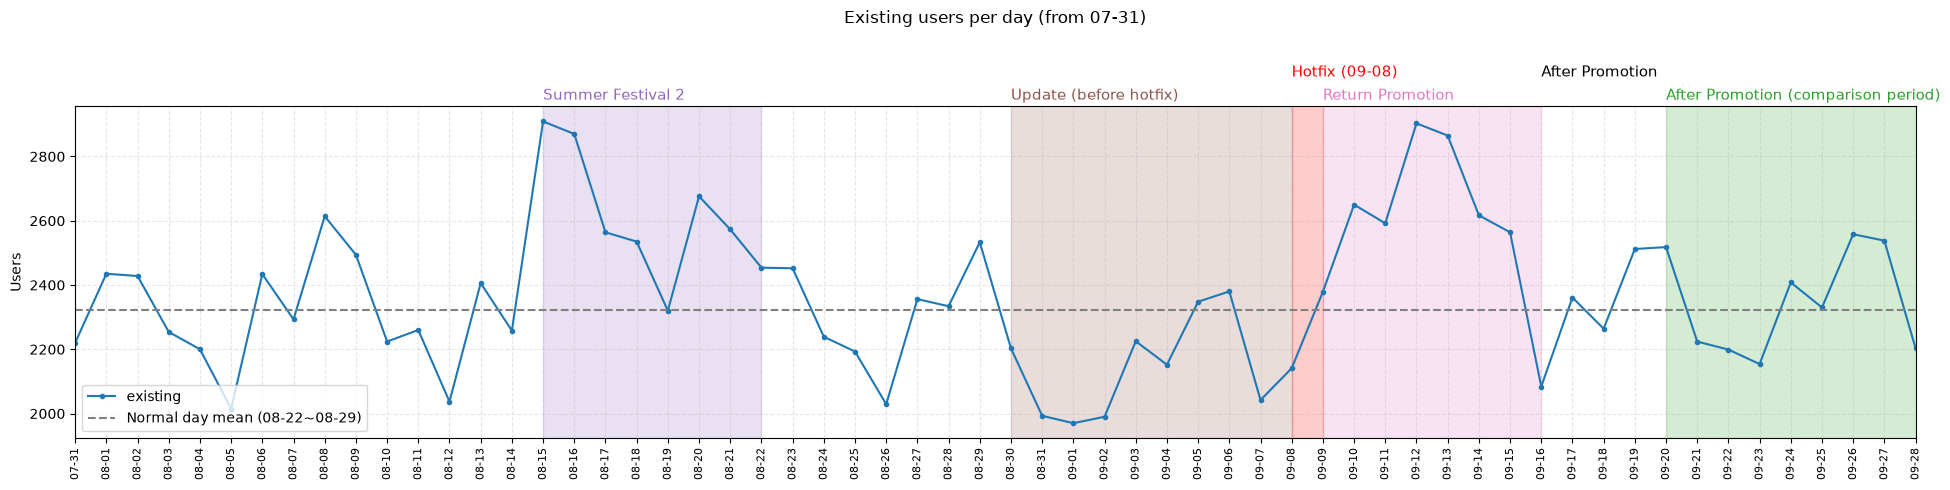

In [14]:
# 시각화: 일별 기존 유저 DAU (7/31 이후, 기간 음영은 2-1과 동일)
existing_daily = dau_type["existing"]
base_existing_mean = existing_base_mean

fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(existing_daily.index, existing_daily, marker="o", markersize=3, label="existing")
ax.axhline(base_existing_mean, color="gray", linestyle="--", label="Normal day mean (08-22~08-29)")
ax.set_title("Existing users per day (from 07-31)", pad=60)
ax.set_ylabel("Users")
ax.set_xlim(existing_daily.index.min(), existing_daily.index.max())
ax.legend(loc="lower left")
ax.grid(alpha=0.3, linestyle="--")

# 기간 음영과 그래프 위쪽 이름 (종료 후는 아래에서 따로 표시)
for name, label, color, y_text in period_styles:
    if name == "복귀 지원 프로모션 종료 후":
        continue
    start, end = periods[name]
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end) + pd.Timedelta(days=1)
    ax.axvspan(start_date, end_date, color=color, alpha=0.2)
    ax.text(start_date, y_text, label, transform=ax.get_xaxis_transform(), fontsize=11, color=color)

# 프로모션 종료 후: 분류 기간(9/16~)은 음영 없이 이름만, 비교 구간(9/20~9/28)만 음영
after_start = pd.Timestamp(periods["복귀 지원 프로모션 종료 후"][0])
ax.text(after_start, 1.09, "After Promotion", transform=ax.get_xaxis_transform(), fontsize=11, color="black")

compare_start, compare_end = hotfix_periods["복귀 지원 프로모션 종료 후"]
compare_start_date = pd.Timestamp(compare_start)
compare_end_date = pd.Timestamp(compare_end) + pd.Timedelta(days=1)
ax.axvspan(compare_start_date, compare_end_date, color="tab:green", alpha=0.2)
ax.text(compare_start_date, 1.02, "After Promotion (comparison period)", transform=ax.get_xaxis_transform(),
        fontsize=11, color="tab:green")

# x축: 일자별 눈금, 90도 회전
ax.set_xticks(existing_daily.index)
ax.set_xticklabels(existing_daily.index.strftime("%m-%d"), rotation=90, fontsize=8)

plt.tight_layout()
plt.show()


[전체 유저 DAU]


,비교 기간,평시 기간,평시 일평균,DAU 일평균,평시 대비(%)
기간,,,,,
성장 개편 업데이트 이후 핫픽스 전,2026-08-30~2026-09-07,2026-08-22~2026-08-29,"2,680","2,360",-11.9%
복귀 지원 프로모션 종료 후,2026-09-20~2026-09-28,2026-08-22~2026-08-29,"2,680","2,576",-3.9%


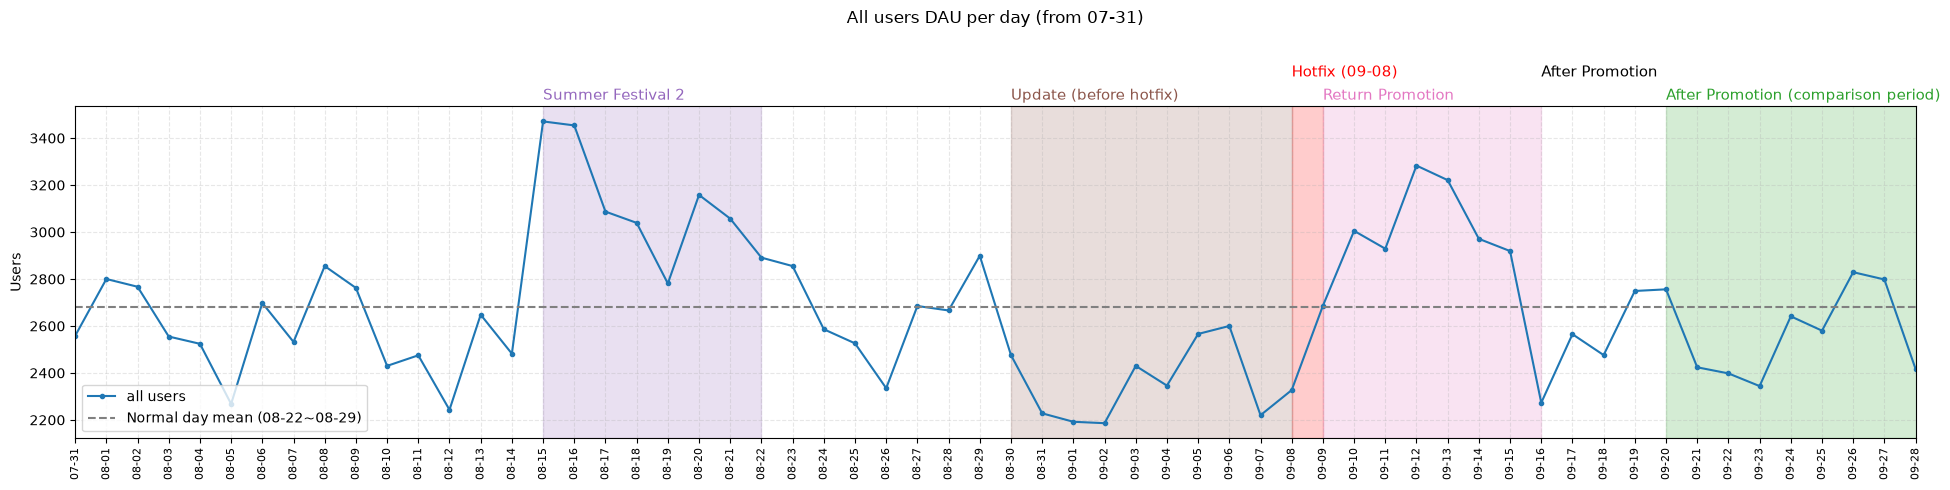

In [15]:
# 전체 유저 DAU: 평시(8/22~8/29) 대비 핫픽스 전, 종료 후 증감률
total_base_mean = dau.loc[hotfix_base_start:hotfix_base_end].mean()

rows = []
for name, (start, end) in hotfix_periods.items():
    period_mean = dau.loc[start:end].mean()
    change_base = (period_mean / total_base_mean - 1) * 100
    period_label = start + "~" + end

    rows.append({"기간": name, "비교 기간": period_label, "평시 기간": hotfix_base_label,
                 "평시 일평균": total_base_mean, "DAU 일평균": period_mean, "평시 대비(%)": change_base})

total_table = pd.DataFrame(rows).set_index("기간")

total_fmt = {"평시 일평균": "{:,.0f}", "DAU 일평균": "{:,.0f}", "평시 대비(%)": "{:+.1f}%"}
print("\n[전체 유저 DAU]")
display(total_table.style.format(total_fmt))


# 시각화: 일별 전체 유저 DAU (7/31 이후, 기간 음영은 2-1과 동일)
total_daily = dau.loc[type_start:]

fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(total_daily.index, total_daily, marker="o", markersize=3, label="all users")
ax.axhline(total_base_mean, color="gray", linestyle="--", label="Normal day mean (08-22~08-29)")
ax.set_title("All users DAU per day (from 07-31)", pad=60)
ax.set_ylabel("Users")
ax.set_xlim(total_daily.index.min(), total_daily.index.max())
ax.legend(loc="lower left")
ax.grid(alpha=0.3, linestyle="--")

# 기간 음영과 그래프 위쪽 이름 (종료 후는 아래에서 따로 표시)
for name, label, color, y_text in period_styles:
    if name == "복귀 지원 프로모션 종료 후":
        continue
    start, end = periods[name]
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end) + pd.Timedelta(days=1)
    ax.axvspan(start_date, end_date, color=color, alpha=0.2)
    ax.text(start_date, y_text, label, transform=ax.get_xaxis_transform(), fontsize=11, color=color)

# 프로모션 종료 후: 분류 기간(9/16~)은 음영 없이 이름만, 비교 구간(9/20~9/28)만 음영
after_start = pd.Timestamp(periods["복귀 지원 프로모션 종료 후"][0])
ax.text(after_start, 1.09, "After Promotion", transform=ax.get_xaxis_transform(), fontsize=11, color="black")

compare_start, compare_end = hotfix_periods["복귀 지원 프로모션 종료 후"]
compare_start_date = pd.Timestamp(compare_start)
compare_end_date = pd.Timestamp(compare_end) + pd.Timedelta(days=1)
ax.axvspan(compare_start_date, compare_end_date, color="tab:green", alpha=0.2)
ax.text(compare_start_date, 1.02, "After Promotion (comparison period)", transform=ax.get_xaxis_transform(),
        fontsize=11, color="tab:green")

# x축: 일자별 눈금, 90도 회전
ax.set_xticks(total_daily.index)
ax.set_xticklabels(total_daily.index.strftime("%m-%d"), rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

### 4-2. 통계적 가설 검정: 핫픽스 전 vs 프로모션 종료 후
- H0(귀무가설): 프로모션 종료 후(9/20~9/28) 기존 유저 일평균 수는 핫픽스 전(8/30~9/7)과 차이가 없다
- H1(대립가설): 프로모션 종료 후 기존 유저 일평균 수는 핫픽스 전과 차이가 있다
- 종료 후는 핫픽스 전과 동일 기간·동일 요일(일~월요일, 총 9일)로 맞춘 9/20~9/28 사용

In [16]:
# 핫픽스 전 vs 복귀 지원 프로모션 종료 후(9/20~9/28): 일별 기존 유저 수 비교 (Mann-Whitney U, 양측)
labels = date_period.reindex(dau_type.index)
before_values = dau_type.loc[labels == "성장 개편 업데이트 이후 핫픽스 전", "existing"]
after_start, after_end = hotfix_periods["복귀 지원 프로모션 종료 후"]
after_values = dau_type.loc[after_start:after_end, "existing"]

before_mean = before_values.mean()
after_mean = after_values.mean()
change = (after_mean / before_mean - 1) * 100
p_value = mannwhitneyu(before_values, after_values, alternative="two-sided").pvalue

hotfix_test = pd.DataFrame({
    "핫픽스 전 일평균": [before_mean],
    "종료 후 일평균": [after_mean],
    "핫픽스 전 대비(%)": [change],
    "p-value": [p_value],
    "유의(p<0.05)": [p_value < 0.05],
}, index=["핫픽스 전 vs 복귀 지원 프로모션 종료 후"])

hotfix_fmt = {"핫픽스 전 일평균": "{:,.0f}", "종료 후 일평균": "{:,.0f}", "핫픽스 전 대비(%)": "{:+.1f}%", "p-value": "{:.4f}"}
display(hotfix_test.style.format(hotfix_fmt))

,핫픽스 전 일평균,종료 후 일평균,핫픽스 전 대비(%),p-value,유의(p<0.05)
핫픽스 전 vs 복귀 지원 프로모션 종료 후,"2,145","2,348",+9.5%,0.0379,True


- 핫픽스 전 vs 복귀 지원 프로모션 종료 후 기존 유저 일평균 DAU 차이가 유의해(p-value = 0.0379), 귀무가설을 기각함.  
  프로모션 종료 후 기존 유저 일평균 DAU가 핫픽스 전보다 증가해, 경험치 하향폭 완화가 효과가 있었던 것으로 판단됨

- 또한 복귀 지원 프로모션 종료 후 기존 유저 DAU가 평시 수준으로 회복되어(직전 평시 **8/22~8/29** 대비 +1.0%), 유저들이 경험치 하향에 민감하게 반응한 것으로 보임

## 5. 매출 기여 유저 유형·상품 가격 확인

### 5-1. 유저 유형별 매출 기여
- **목적**: 여름 축제 2부와 복귀 지원 프로모션의 매출 증가분(프로모션 일평균 매출 - 직전 평시 일평균 매출)을 신규·기존·복귀 유저로 나누어, 어느 유형이 매출 증가에 기여했는지 확인하고자 함  
  (평시: 2부 **8/8~8/14**, 복귀 지원 **8/22~8/28**)

- **방법**
    - 결제는 결제한 날의 유저 유형으로 분류함 (유형 구분은 7/31 이후만 가능해 여름 축제 1부는 제외함)
    - 기여 비중 = 유형별 매출 증가분 ÷ 세 유형 매출 증가분의 합
    - 유형별 결제 전환율, ARPU, ARPPU는 기간 안의 값을 합산해 계산함  
      (결제 전환율 = 결제 유저 수 합 ÷ 접속 유저 수 합, ARPU = 매출 합 ÷ 접속 유저 수 합, ARPPU = 매출 합 ÷ 결제 유저 수 합)
    - 유형별 차이는 검정하지 않고 일평균 값으로 비교함

- **한계점**
    - 결제 유저 수가 적은 유형은 값이 크게 흔들릴 수 있음
    - 복귀 지원 프로모션의 직전 평시(8/22~8/28)에는 여름 축제 2부 가입자가 D14 안에 포함되어, 신규 유저의 평시 대비 증감이 실제보다 크게 나타났을 가능성이 있음

In [17]:
# 결제 건에 결제한 날의 유저 유형 붙이기 (유형 구분이 가능한 7/31 이후)
pay_typed = payments_clean.copy()
pay_typed["date"] = pay_typed["paid_at"].dt.normalize()
pay_typed = pay_typed[pay_typed["date"] >= type_start]

user_type_by_day = act[["user_id", "date", "user_type"]]
pay_typed = pay_typed.merge(user_type_by_day, on=["user_id", "date"], how="left")

# 유형이 붙지 않은 결제 건 확인 (0건이어야 유형별 매출 합계가 전체 매출과 같음)
n_no_type = pay_typed["user_type"].isna().sum()
print(f"유형이 붙지 않은 결제 건: {n_no_type:,}건")

# 날짜별 유형별 매출, 결제 유저 수 (결제가 없는 날은 0)
revenue_type = pay_typed.groupby(["date", "user_type"])["amount_krw"].sum().unstack(fill_value=0)
revenue_type = revenue_type.reindex(index=dau_type.index, columns=type_cols, fill_value=0)

payers_type = pay_typed.groupby(["date", "user_type"])["user_id"].nunique().unstack(fill_value=0)
payers_type = payers_type.reindex(index=dau_type.index, columns=type_cols, fill_value=0)

유형이 붙지 않은 결제 건: 0건


In [18]:
# 프로모션별 유형별 매출 비중 변화, 결제 전환율·ARPU·ARPPU (직전 평시 vs 프로모션)
contrib_periods = ["여름 축제 2부", "복귀 지원 프로모션"]
type_labels = date_period.reindex(dau_type.index)

contrib_rows = []
type_metric_rows = []
gain_by_promo = {}

for name in contrib_periods:
    base_start, base_end = base_periods[name]
    base_label = base_start + "~" + base_end
    is_promo = type_labels == name

    # 유형별 일평균 DAU, 매출 (직전 평시, 프로모션)
    base_dau = dau_type.loc[base_start:base_end].mean()
    promo_dau = dau_type[is_promo].mean()
    base_revenue = revenue_type.loc[base_start:base_end].mean()
    promo_revenue = revenue_type[is_promo].mean()

    # 유형별 매출 증가분(원), 다른 셀 재사용용
    revenue_gain = promo_revenue - base_revenue
    gain_by_promo[name] = revenue_gain

    # 유형별 매출 비중(%)과 프로모션-직전 평시 비중 차이(%p)
    base_share = base_revenue / base_revenue.sum() * 100
    promo_share = promo_revenue / promo_revenue.sum() * 100
    share_diff = promo_share - base_share

    # 유형별 기간 합산 값 (접속 유저 수, 결제 유저 수, 매출)
    base_users = dau_type.loc[base_start:base_end].sum()
    promo_users = dau_type[is_promo].sum()
    base_payers = payers_type.loc[base_start:base_end].sum()
    promo_payers = payers_type[is_promo].sum()
    base_revenue_sum = revenue_type.loc[base_start:base_end].sum()
    promo_revenue_sum = revenue_type[is_promo].sum()

    # 유형별 결제 전환율(%), ARPU, ARPPU
    base_conv = base_payers / base_users * 100
    promo_conv = promo_payers / promo_users * 100
    base_arpu = base_revenue_sum / base_users
    promo_arpu = promo_revenue_sum / promo_users
    base_arppu = base_revenue_sum / base_payers
    promo_arppu = promo_revenue_sum / promo_payers

    for col in type_cols:
        contrib_rows.append({
            "프로모션": name,
            "유형": col,
            "직전 평시 기간": base_label,
            "직전 평시 DAU": base_dau[col],
            "프로모션 DAU": promo_dau[col],
            "직전 평시 일평균 매출": base_revenue[col],
            "프로모션 일평균 매출": promo_revenue[col],
            "직전 평시 매출 비중(%)": base_share[col],
            "프로모션 매출 비중(%)": promo_share[col],
            "매출 비중 차이(%p)": share_diff[col],
        })
        type_metric_rows.append({
            "프로모션": name,
            "유형": col,
            "평시 기간": base_label,
            "평시 결제 유저 수": base_payers[col],
            "프로모션 결제 유저 수": promo_payers[col],
            "평시 결제 전환율(%)": base_conv[col],
            "프로모션 결제 전환율(%)": promo_conv[col],
            "평시 ARPU": base_arpu[col],
            "프로모션 ARPU": promo_arpu[col],
            "평시 ARPPU": base_arppu[col],
            "프로모션 ARPPU": promo_arppu[col],
        })
contrib_table = pd.DataFrame(contrib_rows).set_index(["프로모션", "유형"])
type_metric_table = pd.DataFrame(type_metric_rows).set_index(["프로모션", "유형"])

contrib_fmt = {
    "직전 평시 DAU": "{:,.0f}",
    "프로모션 DAU": "{:,.0f}",
    "직전 평시 일평균 매출": "{:,.0f}",
    "프로모션 일평균 매출": "{:,.0f}",
    "직전 평시 매출 비중(%)": "{:.1f}",
    "프로모션 매출 비중(%)": "{:.1f}",
    "매출 비중 차이(%p)": "{:+.1f}",
}
type_metric_fmt = {
    "평시 결제 유저 수": "{:,.0f}",
    "프로모션 결제 유저 수": "{:,.0f}",
    "평시 결제 전환율(%)": "{:.2f}",
    "프로모션 결제 전환율(%)": "{:.2f}",
    "평시 ARPU": "{:,.0f}",
    "프로모션 ARPU": "{:,.0f}",
    "평시 ARPPU": "{:,.0f}",
    "프로모션 ARPPU": "{:,.0f}",
}

print("\n[유형별 매출 비중 변화]")
display(contrib_table.style.format(contrib_fmt))
print("\n[유형별 결제 전환율, ARPU, ARPPU (기간 합산)]")
display(type_metric_table.style.format(type_metric_fmt))


[유형별 매출 비중 변화]



[유형별 결제 전환율, ARPU, ARPPU (기간 합산)]


**결과 해석**
- 두 프로모션 모두 매출 증가분의 대부분이 기존 유저에서 나옴 (직전 평시 대비 일평균 증가분, 여름 축제 2부 +675,086원, 복귀 지원 프로모션 +313,657원)

- 여름 축제 2부는 기존 유저의 매출 비중이 97.2%에서 90.8%로 낮아졌으나(-6.5%p), 신규 유저 매출이 더 크게 늘어 신규 비중(2.6% → 9.2%)이 커진 영향으로 보임. 기존 유저의 일평균 매출 자체는 증가함

- **여름 축제 2부 기존 유저**는 결제 전환율이 1.08%에서 1.59%로 오르고 ARPPU는 비슷해, **결제자 수 증가와 결제 전환율 증가가 매출 증가에 기여**한 것으로 보임

- **복귀 지원 프로모션의 복귀 유저는** DAU가 77명에서 210명으로 늘었지만 결제 전환율은 0.00%에서 0.14%에 그쳐, **복귀 유저가 결제로 이어지지 않았을 가능성**이 있음

- 복귀 지원 프로모션의 신규 유저 매출 증가분(-36,929원)과 매출 비중 감소(-4.4%p), 기존 유저 매출 비중 증가(+4.3%p)는 직전 평시에 여름 축제 2부 가입자가 포함된 영향일 가능성이 있어 해석에 주의가 필요함

- 복귀 유저는 결제 유저 수가 매우 적어(여름 축제 2부 프로모션 기간 0명), 복귀 유저의 결제 지표는 해석에 주의가 필요함

### 5-2. 결제 이력별 결제 현황
- **목적**: 프로모션 기간의 결제 증가가 결제 이력이 없던 유저의 첫 결제에서 나왔는지, 이미 결제한 적이 있는 유저의 재결제에서 나왔는지 확인하고자 함  
  (직전 평시: 1부 **7/14~7/20**, 2부 **8/8~8/14**, 복귀 지원 **8/22~8/28**)

- **방법**
    - 프로모션과 직전 평시 각각에서, 기간 안에 접속한 유저를 기간 시작 전 결제 기록 유무로 나눔  
      (결제 이력 없음 = 기간 시작 전 결제 기록이 없는 유저로, 기간 중 처음 결제하면 해당 기간 동안 첫 결제로 봄 / 결제 이력 있음 = 기간 시작 전 결제 기록이 있는 유저로, 기간 중 결제하면 재결제로 봄)
    - 접속 유저 수와 결제 유저 수는 기간 안의 고유 유저 수이고, 결제 전환율 = 결제 유저 수 ÷ 접속 유저 수로 계산함 (5-1의 일 합산 방식과 다름)

- **한계점**
    - 로그가 7/1부터라 그 이전 결제 기록은 확인할 수 없어, 결제 이력이 없는 유저에 7/1 이전 결제자가 포함될 수 있음 (관측 기간이 짧은 여름 축제 1부일수록 영향이 큼)
    - 프로모션이 직전 평시보다 늦게 시작해 결제 이력을 확인할 수 있는 기간이 더 길어, 결제 이력이 있는 유저가 프로모션에서 더 많이 잡혔을 가능성이 있음
    - 결제 유저 수가 적은 구분은 값이 크게 흔들릴 수 있음

In [19]:
# 프로모션·직전 평시 접속 유저를 기간 시작 전 결제 이력 유무로 나누어 비교

# 결제일(날짜만)
pay_hist = payments_clean.copy()
pay_hist["date"] = pay_hist["paid_at"].dt.normalize()

hist_rows = []
for name in promo_periods:
    base_start, base_end = base_periods[name]
    promo_start, promo_end = periods[name]
    compare_periods = [
        ("직전 평시", base_start, base_end),
        ("프로모션", promo_start, promo_end),
    ]

    for label, start, end in compare_periods:
        start_day = pd.Timestamp(start)
        end_day = pd.Timestamp(end)

        # 기간 시작 전에 결제 기록이 있는 유저 (관측 시작일 이후 기록 기준)
        prior_payers = pay_hist.loc[pay_hist["date"] < start_day, "user_id"].unique()

        # 기간 중 접속 유저와 결제 기록
        in_period_act = daily_clean["date"].between(start_day, end_day)
        period_users = pd.Series(daily_clean.loc[in_period_act, "user_id"].unique())
        in_period_pay = pay_hist["date"].between(start_day, end_day)
        period_pay = pay_hist[in_period_pay]

        # 기간 전체 매출 (매출 비중 계산용)
        period_revenue = period_pay["amount_krw"].sum()

        # 접속 유저를 결제 이력 유무로 구분
        has_prior = period_users.isin(prior_payers)
        group_users = {
            "결제 이력 없음(첫 결제)": period_users[~has_prior],
            "결제 이력 있음(재결제)": period_users[has_prior],
        }

        for group, group_ids in group_users.items():
            group_pay = period_pay[period_pay["user_id"].isin(group_ids)]

            # 접속 유저 수, 결제 유저 수, 매출
            n_users = len(group_ids)
            n_payers = group_pay["user_id"].nunique()
            revenue = group_pay["amount_krw"].sum()

            # 결제 전환율(%), ARPPU, 매출 비중(%)
            conv = n_payers / n_users * 100
            arppu = revenue / n_payers if n_payers > 0 else np.nan
            revenue_share = revenue / period_revenue * 100

            hist_rows.append({
                "프로모션": name,
                "구분": label,
                "기간": start + "~" + end,
                "결제 이력": group,
                "접속 유저 수": n_users,
                "결제 유저 수": n_payers,
                "결제 전환율(%)": conv,
                "매출": revenue,
                "매출 비중(%)": revenue_share,
                "ARPPU": arppu,
            })

hist_table = pd.DataFrame(hist_rows).set_index(["프로모션", "구분", "결제 이력"])

hist_fmt = {
    "접속 유저 수": "{:,.0f}",
    "결제 유저 수": "{:,.0f}",
    "결제 전환율(%)": "{:.2f}",
    "매출": "{:,.0f}",
    "매출 비중(%)": "{:.1f}",
    "ARPPU": "{:,.0f}",
}

print("\n[결제 이력별 결제 현황]")
display(hist_table.style.format(hist_fmt))


[결제 이력별 결제 현황]


**결과 해석**

- 매출 차이가 유의했던 여름 축제 1부와 2부에서는 재결제 유저의 결제 전환율이 각각 11.57%p(11.19% → 22.76%), 5.89%p(10.80% → 16.69%)로 크게 오른 반면,  
  첫 결제 유저는 0.96%p(2.00% → 2.96%), 0.68%p(1.23% → 1.91%) 오르는 데 그쳐 결제 이력 유무에 따른 전환율 상승폭 차이가 뚜렷하게 나타남

- 재결제 유저의 결제 전환율이 높게 나타난 것으로 보아, 프로모션 상품 매력이 전반적으로 부족했다기보다 **기존 결제 경험이 추가 결제에 대한 심리적·행동적 허들을 낮췄을 가능성**이 있음

- 첫 결제 유저는 여름 축제 1부 프로모션 기간 접속 유저 중 95.48%, 2부에서는 90.55%를 차지함.  
  당시 ARPPU가 유지되었다는 가정하에 첫 결제 전환율이 1%p 더 높았다면, 여름 축제 1부는 약 333.8만 원, 2부는 약 280.2만 원의 추가 매출이 발생했을 것으로 추정됨

- 결제 이력이 없는 유저에게 기존 저가(1,100원대) 상품의 노출·강조를 통해 첫 결제를 유도했을 때 첫 결제 전환율을 높일 수 있을지 A/B 테스트로 검증해 보는 것이 좋아 보임

### 5-3. 프로모션 기간 가격대별 결제 건수
- 프로모션 기간에 어떤 가격대의 결제가 많았는지 일별 결제 건수로 확인함
- 가격대별 결제 건수 누적 그래프(실제 건수)와 100% 누적 그래프(비중)로 비교함
- 프로모션별 가격대 비중은 직전 평시(1부 **7/14~7/20**, 2부 **8/8~8/14**, 복귀 지원 **8/22~8/28**)와 비교함
- 평시 7일의 결제 건수가 많지 않아, 가격대 비중의 작은 차이는 해석에 주의가 필요함

In [20]:
# 가격대별 일별 결제 건수

# 결제일(날짜만)과 가격대
pay = payments_clean.copy()
pay["date"] = pay["paid_at"].dt.normalize()

# 가격대 순서 (낮은 가격 → 높은 가격)
price_order = sorted(pay["amount_krw"].unique())

# 날짜 x 가격대 결제 건수 (결제가 없는 날은 0)
pay_count = pay.groupby(["date", "amount_krw"])["user_id"].count().unstack(fill_value=0)
pay_count = pay_count.reindex(index=all_dates, columns=price_order, fill_value=0)

# 날짜별 가격대 비중(%)
pay_count_total = pay_count.sum(axis=1)
pay_count_share = pay_count.div(pay_count_total, axis=0) * 100

pay_count.head()

amount_krw,1100,5500,11000,33000,55000,110000
2026-07-01,1,2,3,4,5,2
2026-07-02,2,4,4,5,5,3
2026-07-03,1,4,7,6,5,4
2026-07-04,3,6,6,7,6,3
2026-07-05,1,4,5,7,7,3


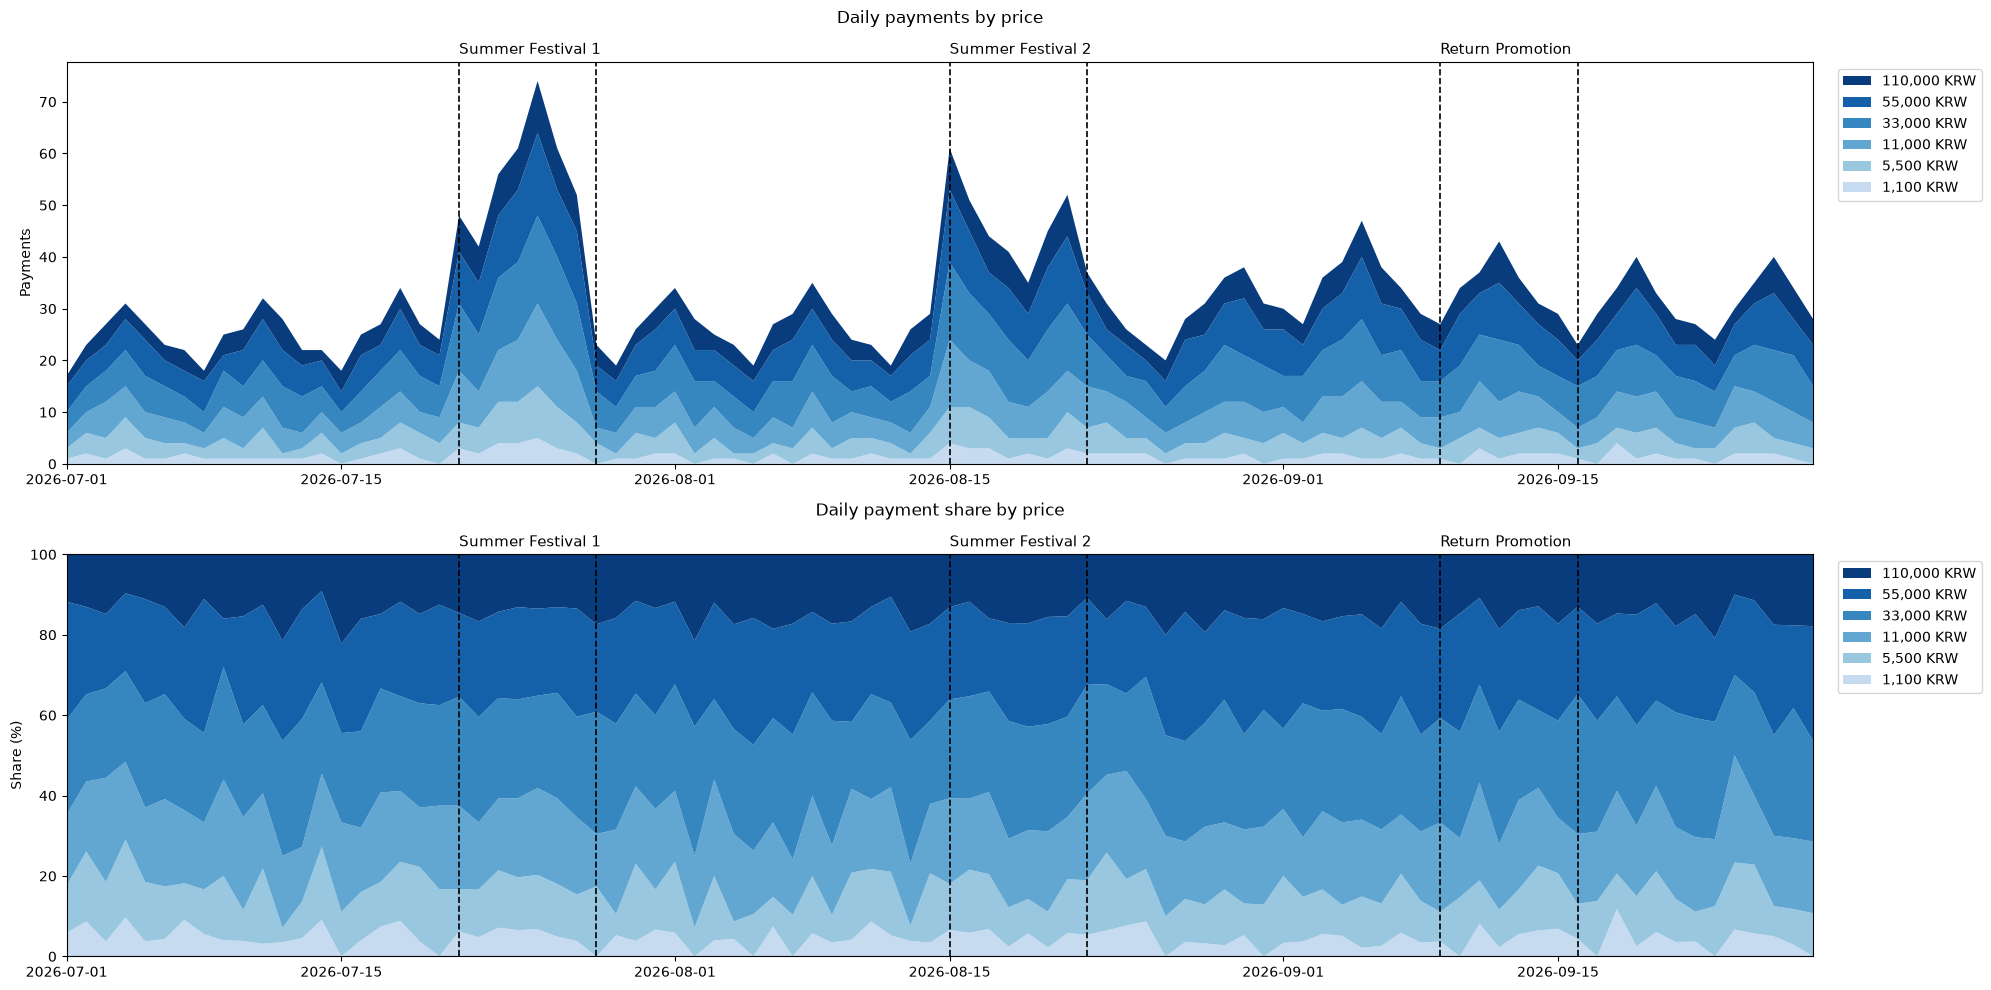

In [21]:
# 시각화: 가격대별 결제 건수 누적 그래프 (위: 실제 건수, 아래: 비중 100%)

# 범례 이름 (예: 1,100 KRW)
price_labels = []
for price in price_order:
    price_labels.append(f"{price:,} KRW")

# 가격대 색: 낮은 가격은 연하게, 높은 가격은 진하게
price_colors = plt.cm.Blues(np.linspace(0.25, 0.95, len(price_order)))

# (데이터, 그래프 제목, y축 이름)
charts = [
    (pay_count, "Daily payments by price", "Payments"),
    (pay_count_share, "Daily payment share by price", "Share (%)"),
]

# 프로모션 기간: (기간 이름, 그래프 표시 이름)
promo_styles = [
    ("여름 축제 1부", "Summer Festival 1"),
    ("여름 축제 2부", "Summer Festival 2"),
    ("복귀 지원 프로모션", "Return Promotion"),
]

fig, axes = plt.subplots(2, 1, figsize=(20, 10))

for ax, (data, title, ylabel) in zip(axes, charts):
    ax.stackplot(data.index, data.T.values, labels=price_labels, colors=price_colors)

    # 프로모션 시작일·종료일 점선과 이름 (누적 색을 가리지 않도록 음영 대신 선 사용)
    for name, label in promo_styles:
        start, end = periods[name]
        start_day = pd.Timestamp(start)
        end_day = pd.Timestamp(end) + pd.Timedelta(days=1)
        ax.axvline(start_day, color="black", linestyle="--", linewidth=1.2)
        ax.axvline(end_day, color="black", linestyle="--", linewidth=1.2)
        ax.text(start_day, 1.02, label, transform=ax.get_xaxis_transform(), fontsize=11)

    ax.set_title(title, pad=28)
    ax.set_ylabel(ylabel)
    ax.set_xlim(all_dates[0], all_dates[-1])
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), reverse=True)

axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [22]:
# 프로모션별 가격대 결제 건수 비중: 직전 평시 vs 프로모션
price_labels_map = dict(zip(price_order, price_labels))
pay_labels = date_period.reindex(pay_count.index)

share_rows = []
diff_rows = []
for name in promo_periods:
    base_start, base_end = base_periods[name]
    base_label = base_start + "~" + base_end

    # 평시와 프로모션의 가격대별 결제 건수 합계
    base_count = pay_count.loc[base_start:base_end].sum()
    promo_count = pay_count[pay_labels == name].sum()

    # 가격대별 비중(%)과 차이(%p)
    base_share = base_count / base_count.sum() * 100
    promo_share = promo_count / promo_count.sum() * 100
    share_diff = promo_share - base_share

    base_row = {"프로모션": name, "구분": "직전 평시", "기간": base_label, "결제 건수": base_count.sum()}
    promo_row = {"프로모션": name, "구분": "프로모션", "기간": periods[name][0] + "~" + periods[name][1],
                 "결제 건수": promo_count.sum()}
    diff_row = {"프로모션": name}
    for price in price_order:
        price_label = price_labels_map[price]
        base_row[price_label] = base_share[price]
        promo_row[price_label] = promo_share[price]
        diff_row[price_label] = share_diff[price]

    share_rows.append(base_row)
    share_rows.append(promo_row)
    diff_rows.append(diff_row)

share_table = pd.DataFrame(share_rows).set_index(["프로모션", "구분"])
diff_table = pd.DataFrame(diff_rows).set_index("프로모션")

share_fmt = {label: "{:.1f}%" for label in price_labels}
share_fmt["결제 건수"] = "{:,.0f}"
diff_fmt = {label: "{:+.2f}%p" for label in price_labels}

print("[가격대별 결제 건수 비중]")
display(share_table.style.format(share_fmt))
print("\n[가격대별 비중 차이 (프로모션 - 직전 평시)]")
display(diff_table.style.format(diff_fmt))

[가격대별 결제 건수 비중]



[가격대별 비중 차이 (프로모션 - 직전 평시)]


,"1,100 KRW","5,500 KRW","11,000 KRW","33,000 KRW","55,000 KRW","110,000 KRW"
프로모션,,,,,,
여름 축제 1부,+0.75%p,-2.00%p,+1.15%p,+0.83%p,-0.58%p,-0.16%p
여름 축제 2부,+0.30%p,-0.58%p,+0.16%p,+0.97%p,-0.08%p,-0.78%p
복귀 지원 프로모션,-0.46%p,-0.94%p,-0.91%p,-0.11%p,+2.02%p,+0.39%p


## 요약

### 유저 유형 변화
- 여름 축제 1, 2부는 직전 평시보다 기존·복귀 유저가 증가, 복귀 지원 프로모션은 직전 평시보다 기존 유저는 감소, 복귀 유저는 증가함
- 신규 유저는 마케팅 광고가 포함된 여름 축제 1부·2부에서 크게 증가해, 신규 유저는 마케팅에 크게 반응하는 것으로 보임
- 복귀 유저는 마케팅 없이 진행한 복귀 지원 프로모션에서 여름 축제 2부보다 더 많이 증가해, 복귀 보상이 복귀 유저를 끌어오는 데 효과적이었던 것으로 보임

### 주요 지표 변화
- 여름 축제 1부·2부는 매출과 결제 전환율이 직전 평시 대비 유의하게 증가했고 복귀 지원 프로모션은 DAU만 유의하게 증가해, 축제 또는 축제 기간 판매한 상품이 매출 증가에 기여한 것으로 추측됨
  - **한계점**: 축제 기간 판매한 한정 코스튬 판매 상품 데이터가 없어, 어떤 상품이 매출 증가에 기여했는지 확인할 수 없음. 추후 확인 필요
- ARPPU는 세 프로모션 모두 직전 평시와 차이가 유의하지 않아, 매출 증가는 1명당 결제액보다 DAU와 결제 전환율 증가의 영향이 큰 것으로 판단됨

### 성장 개편 업데이트와 핫픽스
- 복귀 지원 프로모션 종료 후에도 평균 기존 유저 DAU가 핫픽스 전보다 높아, 경험치 하향폭 완화(핫픽스)가 효과가 있었던 것으로 보임
- 핫픽스 이후 기존 유저가 평시 수준으로 회복되어, 유저들이 경험치 하향에 민감하게 반응한 것으로 보임

### 매출 기여 유저 유형과 결제 이력
- 여름 축제 2부와 복귀 지원 프로모션 모두 직전 평시 대비 매출 증가분의 대부분이 기존 유저에서 나옴
- 여름 축제 2부 기존 유저는 결제 전환율이 오르고 ARPPU는 비슷해, 결제 유저 수 증가 및 결제 전환율이 매출 증가에 기여한 것으로 보임
- 복귀 지원 프로모션은 복귀 유저가 늘었지만 복귀 유저의 결제 전환율이 0.14%에 그쳐, 복귀 유저가 결제로 이어지지 않았을 가능성이 있음
  - **한계점**: 복귀 유저는 결제 유저 수가 매우 적어 해석에 주의가 필요함(복귀 지원 프로모션에서 2명)
- 프로모션 기간 접속 유저를 결제 이력으로 나누면, 결제 이력이 있는 유저는 접속 유저의 약 5~13%이지만 매출의 36~69%를 차지함
- 여름 축제 1·2부는 직전 평시 대비 결제 전환율이 결제 이력이 없는 유저에서 상대적으로 약 48~55%, 결제 이력이 있는 유저에서 약 55~103% 올라, 결제 이력이 있는 유저의 반응이 더 큰 것으로 보임
  - **한계점**: 결제 이력은 7/1 이후 기록만 확인할 수 있어, 결제 이력이 없는 유저에 이전 결제자가 포함되었을 가능성이 있음

### 가격대별 결제 건수
- 프로모션 기간 가격대별 결제 건수 비중은 직전 평시 대비 차이가 가격대별로 약 2%p 이내로 작아, 특정 가격대가 매출 증가를 이끌었다고 보기 어려움
  - **한계점**: 직전 평시 7일의 결제 건수가 177~196건으로 많지 않아, 작은 차이는 해석에 주의가 필요함